# 1. Import library ที่ต้องการใช้งาน

In [1]:
!pip install pythainlp

In [2]:
import pythainlp
from pythainlp import word_tokenize
from pythainlp.corpus import get_corpus # for getting stopwords

import wordcloud
from wordcloud import WordCloud

import matplotlib.pyplot as plt
import numpy as np
import re

%matplotlib inline
%config InlineBackend.figure_format='retina'

# 2.นำเข้าไฟล์ข้อมูลที่เตรียมไว้(พระราชกรณียกิจของแต่ละรัชกาล)ที่อยู่ในรูป .txt 

In [3]:
file_name='R1.txt'
with open(file_name, encoding='utf8') as f:
    s=f.read()
print(s)

พระราชกรณียกิจด้านการสถาปนากรุงรัตนโกสินทร์เป็นราชธานี
            พระราชกรณียกิจประการแรกที่พระบาทสมเด็จพระพุทธยอดฟ้าจุฬาโลกมหาราชทรงจัดทำเมื่อเสด็จขึ้นครองราชย์ คือการโปรดเกล้าฯ ให้ตั้งกรุงรัตนโกสินทร์เป็นราชธานีใหม่ ทางตะวันออกของแม่น้ำเจ้าพระยา แทนกรุงธนบุรี ด้วยเหตุผลทางด้านยุทธศาสตร์ เนื่องจากกรุงธนบุรีตั้งอยู่บนสองฝั่งแม่น้ำ ทำให้การลำเลียงอาวุธยุทธภัณฑ์ และการรักษาพระนครเป็นไปได้ยาก อีกทั้งพระราชวังเดิมมีพื้นที่จำกัด ไม่สามารถขยายได้ เนื่องจากติดวัดอรุณราชวราราม และวัดโมฬีโลกยาราม ส่วนทางฝั่งกรุงรัตนโกสินทร์นั้นมีความเหมาะสมกว่าตรงที่มีพื้นแผ่นดินเป็นลักษณะหัวแหลม มีแม่น้ำเป็นคูเมืองธรรมชาติ มีชัยภูมิเหมาะสม และสามารถรับศึกได้เป็นอย่างดี
            การสร้างราชธานีใหม่นั้นใช้เวลาทั้งสิ้น ๓ ปี โดยพระบาทสมเด็จพระพุทธยอดฟ้าจุฬาโลกมหาราช ทรงทำพิธียกเสาหลักเมือง เมื่อวันอาทิตย์ เดือน ๖ ขึ้น ๑๐ ค่ำ ปีขาล จศ.๑๑๔๔ ตรงกับวันที่ ๒๑ เมษายน พศ.๒๓๒๕ และโปรดเกล้าฯให้สร้าง พระบรมมหาราชวัง สืบทอดราชประเพณี และสร้างพระอารามหลวงในเขตพระบรมมหาราชวังตามแบบกรุงศรีอยุธยา ซึ่งการสร้างเมืองและพระบรมมห

# 3.ทำการแบ่งคำแล้วแยกแต่ละคำด้วยช่องว่าง 

In [4]:
words = word_tokenize(s)
print(words)

['พระราชกรณียกิจ', 'ด้าน', 'การ', 'สถาปนา', 'กรุงรัตนโกสินทร์', 'เป็น', 'ราชธานี', '\n', '            ', 'พระราชกรณียกิจ', 'ประการ', 'แรก', 'ที่', 'พระ', 'บาท', 'สมเด็จ', 'พระพุทธ', 'ยอด', 'ฟ้า', 'จุฬา', 'โลก', 'มหาราช', 'ทรง', 'จัดทำ', 'เมื่อ', 'เสด็จ', 'ขึ้น', 'ครองราชย์', ' ', 'คือ', 'การ', 'โปรดเกล้าฯ', ' ', 'ให้', 'ตั้ง', 'กรุงรัตนโกสินทร์', 'เป็น', 'ราชธานี', 'ใหม่', ' ', 'ทาง', 'ตะวันออก', 'ของ', 'แม่น้ำ', 'เจ้าพระยา', ' ', 'แทน', 'กรุงธนบุรี', ' ', 'ด้วย', 'เหตุผล', 'ทาง', 'ด้าน', 'ยุทธศาสตร์', ' ', 'เนื่องจาก', 'กรุงธนบุรี', 'ตั้งอยู่', 'บน', 'สอง', 'ฝั่งแม่น้ำ', ' ', 'ทำให้', 'การลำเลียง', 'อาวุธยุทธภัณฑ์', ' ', 'และ', 'การรักษา', 'พระนคร', 'เป็นไปได้', 'ยาก', ' ', 'อีก', 'ทั้ง', 'พระราชวัง', 'เดิม', 'มี', 'พื้นที่', 'จำกัด', ' ', 'ไม่', 'สามารถ', 'ขยาย', 'ได้', ' ', 'เนื่องจาก', 'ติด', 'วัด', 'อรุณราชวราราม', ' ', 'และ', 'วัด', 'โม', 'ฬี', 'โลก', 'ยา', 'ราม', ' ', 'ส่วน', 'ทาง', 'ฝั่ง', 'กรุงรัตนโกสินทร์', 'นั้น', 'มี', 'ความเหมาะสม', 'กว่า', 'ตรง', 'ที่', 'มี', 'พื้น', 'แผ่

In [5]:
all_words = ' '.join(words).lower().strip()
#all_word = re.sub('(\n|\s{2})', '', all_words)
all_words[:1000]

'พระราชกรณียกิจ ด้าน การ สถาปนา กรุงรัตนโกสินทร์ เป็น ราชธานี \n              พระราชกรณียกิจ ประการ แรก ที่ พระ บาท สมเด็จ พระพุทธ ยอด ฟ้า จุฬา โลก มหาราช ทรง จัดทำ เมื่อ เสด็จ ขึ้น ครองราชย์   คือ การ โปรดเกล้าฯ   ให้ ตั้ง กรุงรัตนโกสินทร์ เป็น ราชธานี ใหม่   ทาง ตะวันออก ของ แม่น้ำ เจ้าพระยา   แทน กรุงธนบุรี   ด้วย เหตุผล ทาง ด้าน ยุทธศาสตร์   เนื่องจาก กรุงธนบุรี ตั้งอยู่ บน สอง ฝั่งแม่น้ำ   ทำให้ การลำเลียง อาวุธยุทธภัณฑ์   และ การรักษา พระนคร เป็นไปได้ ยาก   อีก ทั้ง พระราชวัง เดิม มี พื้นที่ จำกัด   ไม่ สามารถ ขยาย ได้   เนื่องจาก ติด วัด อรุณราชวราราม   และ วัด โม ฬี โลก ยา ราม   ส่วน ทาง ฝั่ง กรุงรัตนโกสินทร์ นั้น มี ความเหมาะสม กว่า ตรง ที่ มี พื้น แผ่นดิน เป็น ลักษณะ หัวแหลม   มี แม่น้ำ เป็น คูเมือง ธรรมชาติ   มี ชัยภูมิ เหมาะสม   และ สามารถ รับศึก ได้ เป็น อย่าง ดี \n              การ สร้าง ราชธานี ใหม่ นั้น ใช้เวลา ทั้งสิ้น   ๓   ปี   โดย พระ บาท สมเด็จ พระพุทธ ยอด ฟ้า จุฬา โลก มหาราช   ทรง ทำพิธี ยก เสาหลักเมือง   เมื่อ วันอาทิตย์   เดือน   ๖   ขึ้น   ๑๐   ค่ำ   ปีขาล   จ 

# 4. ทำการสร้าง Stopwords เพื่อนำคำที่ไม่ต้องการออก

In [6]:
stopwords = { 'กล่าว' , 'กว่า' , 'กัน' ,'กับ', 'การ', 'ก็' , 'ก่อน' , 'ขณะ' , 'ขอ' , 'ของ' , 'ขึ้น' ,
             'คง' , 'ครั้ง', 'ความ', 'คือ' ,'จะ', 'จัด', 'จาก','จึง', 'ซึ่ง', 'ดัง','ด้วย','ด้าน','ตั้ง',
             'ตั้งแต่','ตาม','ต่อ','ต่าง','ต่างๆ','ต้อง','ถึง','ถูก','ถ้า','ทั้ง','ทั้งนี้','ทาง','ทำ',
             'ทำให้','ที่','ที่สุด','ทุก','นอกจาก','นัก','นั้น','นำ','นี้','น่า','บาง','ผล','ผ่าน',
             'พบ','พร้อม','มา','มาก','มี','ยัง','รวม','ระหว่าง','รับ','ราย','ร่วม','ลง','วัน',
             'ว่า','สำหรับ','สุด','ส่ง','ส่วน','หนึ่ง','หรือ','หลัง','หลังจาก','หลาย','หาก',
             'อยาก','อยู่','อย่าง','ออก','อะไร','อาจ','อีก','เขา','เข้า','เคย','เฉพาะ','เช่น',
             'เดียว','เดียวกัน','เนื่องจาก','เปิด','เปิดเผย','เป็น','เป็นการ','เพราะ','เพื่อ','เมื่อ',
             'เรา','เริ่ม','เลย','เห็น','เอง','แต่','แบบ','แรก','และ','แล้ว','แห่ง',
             'โดย','ใน','ให้','ได้','ไป','ไม่','ไว้' }
print(type(stopwords))
print(stopwords)

<class 'set'>
{'ทำให้', 'คง', 'เรา', 'ดัง', 'มาก', 'จาก', 'ด้าน', 'พบ', 'แห่ง', 'เริ่ม', 'กัน', 'ตั้งแต่', 'เอง', 'เปิดเผย', 'ที่สุด', 'เห็น', 'แล้ว', 'ทุก', 'ยัง', 'หลังจาก', 'ต้อง', 'ก็', 'ได้', 'เมื่อ', 'เช่น', 'เพราะ', 'ขณะ', 'ทั้ง', 'อย่าง', 'นำ', 'บาง', 'หลัง', 'เป็นการ', 'โดย', 'แต่', 'ไม่', 'และ', 'นัก', 'มา', 'หรือ', 'ว่า', 'เฉพาะ', 'นั้น', 'ส่วน', 'ไป', 'ครั้ง', 'ขึ้น', 'อาจ', 'มี', 'ร่วม', 'ทั้งนี้', 'ตั้ง', 'เปิด', 'เดียว', 'อะไร', 'เลย', 'แบบ', 'ทำ', 'ของ', 'เคย', 'ถ้า', 'น่า', 'จึง', 'เป็น', 'ทาง', 'ต่อ', 'ระหว่าง', 'อยู่', 'ด้วย', 'ต่าง', 'ใน', 'ขอ', 'พร้อม', 'ต่างๆ', 'กับ', 'ไว้', 'เนื่องจาก', 'สุด', 'เพื่อ', 'หาก', 'อีก', 'เขา', 'ให้', 'รวม', 'ผ่าน', 'ที่', 'ผล', 'ออก', 'จะ', 'กล่าว', 'ถึง', 'จัด', 'นอกจาก', 'อยาก', 'วัน', 'หลาย', 'เดียวกัน', 'ความ', 'ถูก', 'คือ', 'ราย', 'ส่ง', 'กว่า', 'ซึ่ง', 'สำหรับ', 'เข้า', 'แรก', 'นี้', 'รับ', 'หนึ่ง', 'การ', 'ก่อน', 'ลง', 'ตาม'}


# 5. ทำการสร้าง WordCloud

5.1 ทำWordCloud ตามรูปร่างที่กำหนด

In [11]:
# read the mask image
from PIL import Image
mask_img_file='elephant.png'
mask = np.array(Image.open(f'mask_image/{mask_img_file}').convert('RGBA'))

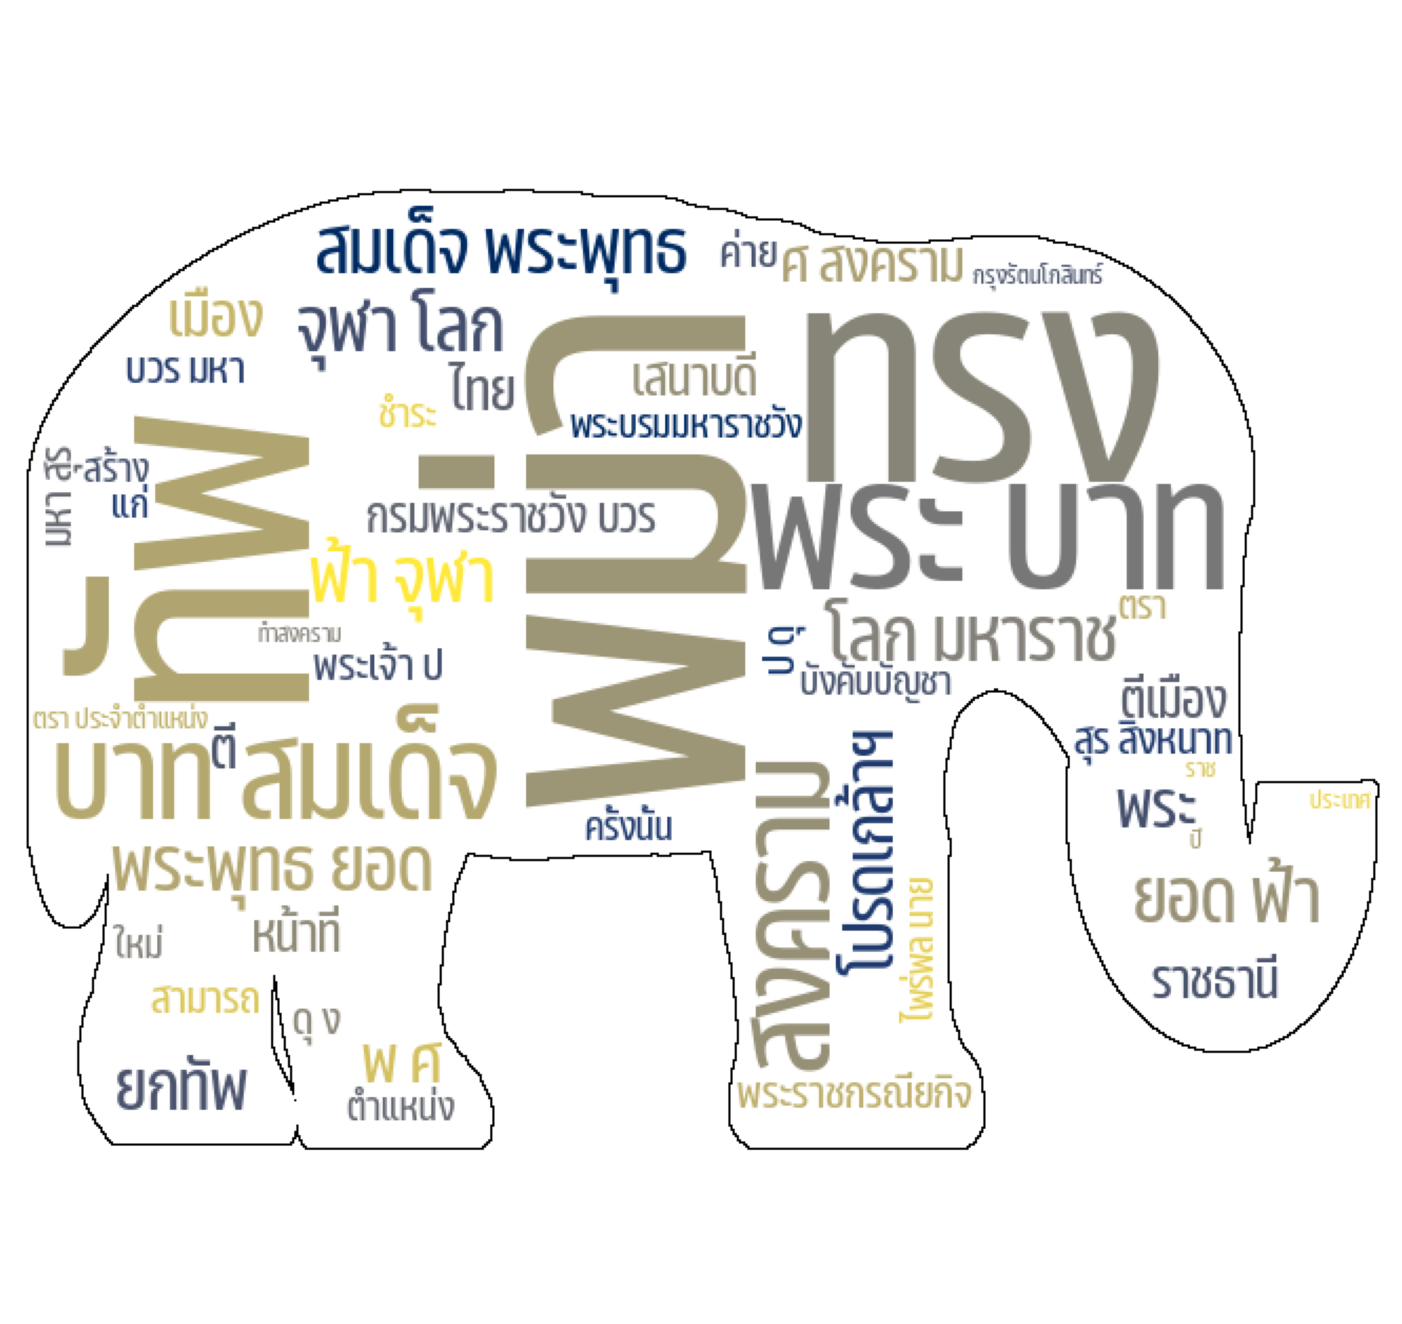

In [12]:
wordcloud = WordCloud(
  font_path="C:/Users/pornw/Downloads/project gcd/FCFlexica[Non-commercial]-Light.ttf",
    stopwords=stopwords,
    width=2000, height=1000,
    colormap='cividis', # https://matplotlib.org/3.3.3/tutorials/colors/colormaps.html
    max_words=50, 
    
    mask=mask,
    contour_width=0.1,
    contour_color='black', # https://matplotlib.org/3.1.0/gallery/color/named_colors.html
    prefer_horizontal=.9,
    
    regexp='[ก-๙]+',
    background_color = 'white').generate(all_words)
plt.figure(figsize = (16, 9))
plt.imshow(wordcloud)
plt.axis('off')
plt.tight_layout(pad=0)
plt.show()

# 6. เซฟรูปภาพ

In [13]:
wordcloud.to_file("wordcloud1.png")